# Lab Task 1



**Task # 01:**

Load a grayscale image and shift the entire image 10 pixels to the left. Fill the empty space on the right with black pixels. Display the original and the shifted image side by side.

In [ ]:
image_path = "/content/cartoon.png"
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from scipy import ndimage
from skimage import color, morphology

%matplotlib inline

In [ ]:
rgb_image = Image.open(image_path).convert("RGB")

gray_image = rgb_image.convert("L")

rgb_array = np.array(rgb_image)
gray_array = np.array(gray_image)

print("RGB shape:", rgb_array.shape)
print("Grayscale shape:", gray_array.shape)

print("RGB data type:", rgb_array.dtype)
print("Grayscale data type:", gray_array.dtype)

RGB shape: (407, 424, 3)
Grayscale shape: (407, 424)
RGB data type: uint8
Grayscale data type: uint8


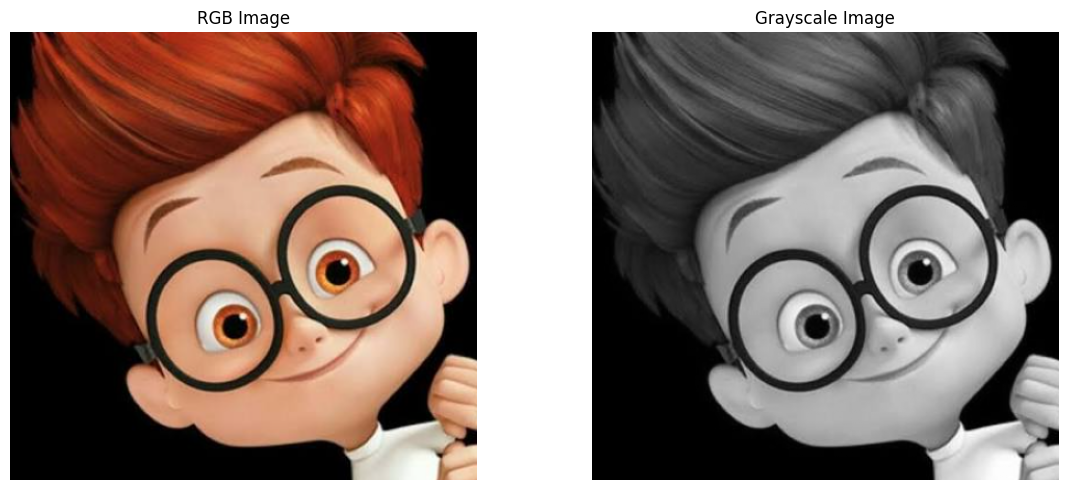

In [ ]:
#step 5: display RGB and grey scale
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rgb_array)
axes[0].set_title("RGB Image")
axes[0].axis("off")

axes[1].imshow(gray_array, cmap="gray")
axes[1].set_title("Grayscale Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
shifted_image = np.zeros_like(gray_image)


In [ ]:
shifted_image[:, :-10] = gray_array[:, 10:]

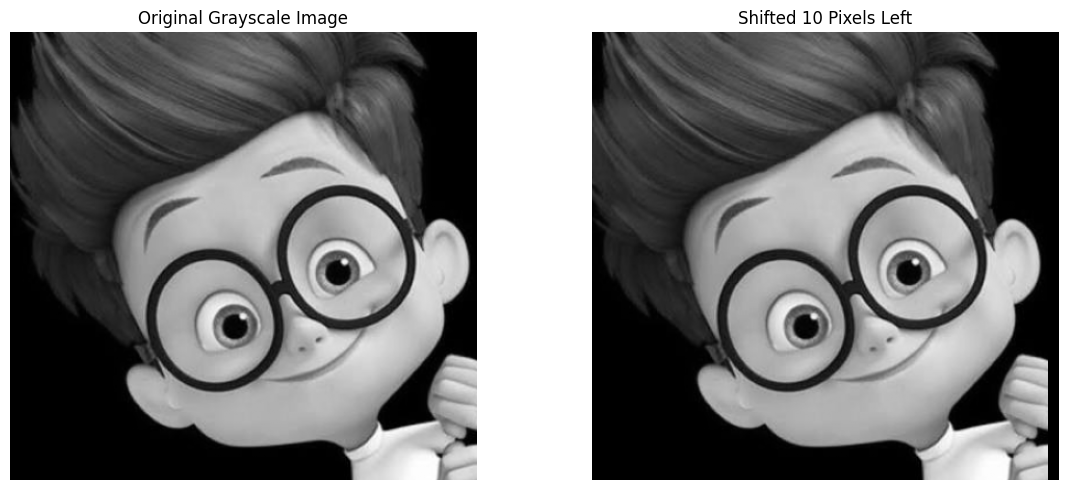

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(shifted_image, cmap="gray")
plt.title("Shifted 10 Pixels Left")
plt.axis("off")

plt.tight_layout()
plt.show()

We shifted the image 10 pixels to the left by moving everything over from the tenth column onward. This left a blank, 10-pixel gap on the right side, which we filled with black.

**Task # 02:**

Create your own 5×5 sharpening kernel (different from the one in the lab). Apply it to a slightly blurred image and compare the result with the standard 3×3 sharpening kernel. Which one looks sharper and which one introduces more noise?*italicized text*

Original
   ->
Slight Blur
    ->
5×5 Sharpening
    ->
Compare with 3×3 Sharpening

In [ ]:
image = Image.open(image_path).convert("L")
gray_image = np.array(image).astype(float)

In [ ]:
blurred_image = ndimage.gaussian_filter(
    gray_image,
    sigma=1
)

In [ ]:
kernel_3x3 = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=float)

In [ ]:
sharpened_3x3 = ndimage.convolve(
    blurred_image,
    kernel_3x3,
    mode="reflect"
)

sharpened_3x3 = np.clip(
    sharpened_3x3,
    0,
    255
)

In [ ]:
kernel_5x5 = np.array([
    [0,  0, -1,  0,  0],
    [0, -1, -2, -1,  0],
    [-1, -2, 20, -2, -1],
    [0, -1, -2, -1,  0],
    [0,  0, -1,  0,  0]
], dtype=float)

In [ ]:
sharpened_5x5 = ndimage.convolve(
    blurred_image,
    kernel_5x5,
    mode="reflect"
)

sharpened_5x5 = np.clip(
    sharpened_5x5,
    0,
    255
)

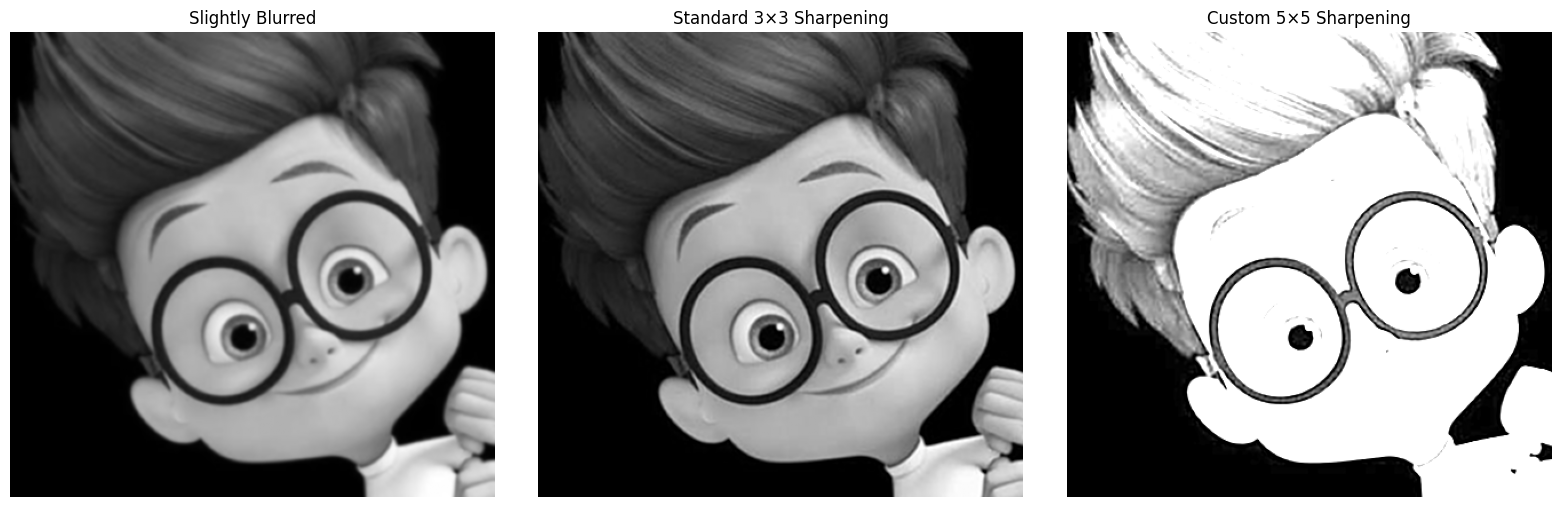

In [ ]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(blurred_image, cmap="gray")
plt.title("Slightly Blurred")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sharpened_3x3, cmap="gray")
plt.title("Standard 3×3 Sharpening")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sharpened_5x5, cmap="gray")
plt.title("Custom 5×5 Sharpening")
plt.axis("off")

plt.tight_layout()
plt.show()

**Task # 03:**

Apply a strong Gaussian blur (sigma = 8) to an image, then try to recover the sharpness using the sharpening filter. Show the original, the blurred version, and the attempt to sharpen it. Comment on how well the details came back.

In [ ]:
image = Image.open(image_path).convert("L")

gray_image = np.array(image).astype(float)

In [ ]:
gaussian_filtered = ndimage.gaussian_filter(
    gray_array.astype(float),
    sigma=1
)

In [ ]:
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=float)

In [ ]:
attempted_sharpen = ndimage.convolve(
    gaussian_filtered,
    sharpen_kernel,
    mode="reflect"
)

attempted_sharpen = np.clip(
    attempted_sharpen,
    0,
    255
)

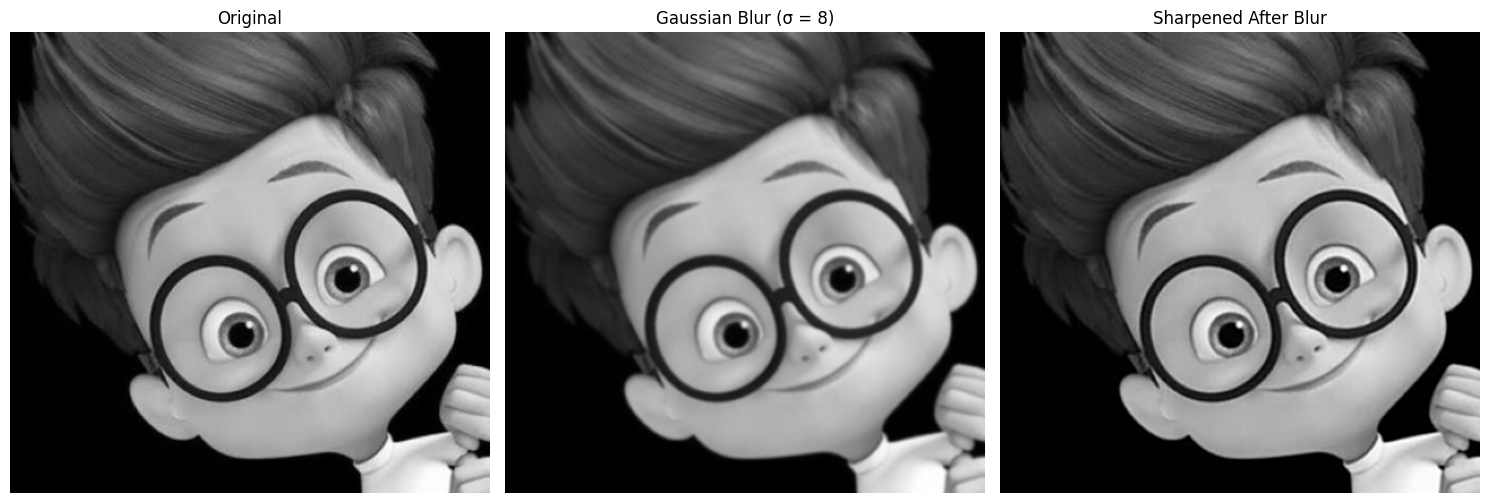

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_filtered, cmap="gray")
plt.title("Gaussian Blur (σ = 8)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(attempted_sharpen, cmap="gray")
plt.title("Sharpened After Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

When you use a Gaussian filter with a high \(\sigma = 8\), you apply a heavy blur that wipes away most of the fine details. If you try to sharpen the image afterward, you will boost the contrast of whatever edges are left. This makes the image look crisper than the purely blurred version. However, you won't get the original fine details back. Because the initial blur completely erased that high-frequency data, the sharpening filter has nothing left to work with. It can enhance the prominent lines that survived, but it cannot recreate information that is already gone.

**Task # 04:**

Take a new image that has a lot of fine detail (for example a text document or a building with many windows). Convert it to grayscale and apply both a 3×3 and a 9×9 box filter. Show all three images and explain which kernel size destroys more detail.

In [ ]:
detail_image = Image.open(
    "/content/picturewithdetail.png"
).convert("L")

detail_gray = np.array(detail_image).astype(float)

In [ ]:
# 3x3
kernel_3x3 = np.ones((3, 3)) / 9

In [ ]:
box_3x3 = ndimage.convolve(
    detail_gray,
    kernel_3x3,
    mode="reflect"
)

In [ ]:
#9x9
kernel_9x9 = np.ones((9, 9)) / 81

In [ ]:
box_9x9 = ndimage.convolve(
    detail_gray,
    kernel_9x9,
    mode="reflect"
)

In [ ]:
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(detail_gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(box_3x3, cmap="gray")
plt.title("3×3 Box Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(box_9x9, cmap="gray")
plt.title("9×9 Box Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

The 9×9 box filter wipes out much more fine detail than the 3×3 filter. Because its larger kernel averages pixels across a much bigger neighborhood, it creates a much stronger smoothing effect. This causes fine edges, text, small windows, and other sharp details to blur together. While the 3×3 filter also smooths the image, its impact is much gentler because it works within a smaller, tighter neighborhood.

**Task # 05:**

Design a sequence that first removes salt and pepper noise with a median filter, then applies a gentle Gaussian filter, then computes Sobel edges on the smoothed image and finally sharpens the smoothed result, display every stage, and write a short analysis of how well the edges were preserved.

In [ ]:
image = Image.open(image_path).convert("L")

original = np.array(image).astype(float)

In [ ]:
noisy = original.copy()

rng = np.random.default_rng(42)

salt_pepper = rng.random(noisy.shape)

noisy[salt_pepper < 0.02] = 0
noisy[salt_pepper > 0.98] = 255

In [ ]:
median_result = ndimage.median_filter(
    noisy,
    size=3
)

In [ ]:
gaussian_result = ndimage.gaussian_filter(
    median_result,
    sigma=1
)

In [ ]:
sobel_x = ndimage.sobel(
    gaussian_result,
    axis=1
)

sobel_y = ndimage.sobel(
    gaussian_result,
    axis=0
)

In [ ]:
sobel_magnitude = np.sqrt(
    sobel_x**2 + sobel_y**2
)
sobel_magnitude = (
    sobel_magnitude /
    sobel_magnitude.max()
) * 255

In [ ]:
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=float)



In [ ]:
sharpened_result = ndimage.convolve(
    gaussian_result,
    sharpen_kernel,
    mode="reflect"
)

sharpened_result = np.clip(
    sharpened_result,
    0,
    255
)

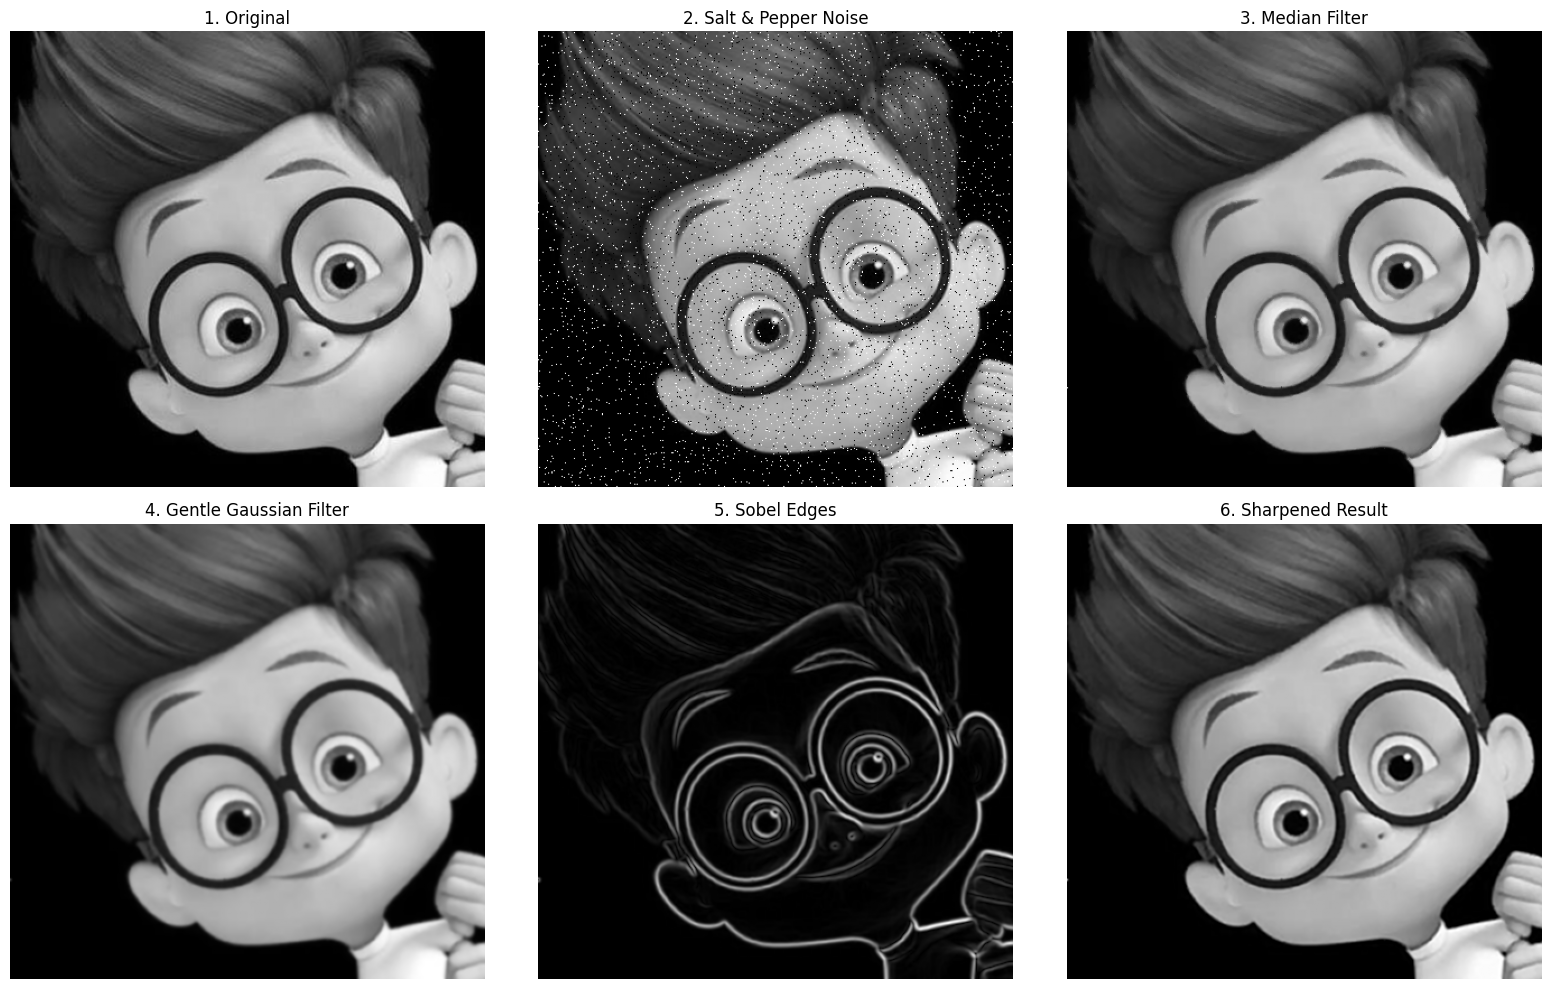

In [ ]:
plt.figure(figsize=(16, 10))

plt.subplot(2, 3, 1)
plt.imshow(original, cmap="gray")
plt.title("1. Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(noisy, cmap="gray")
plt.title("2. Salt & Pepper Noise")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(median_result, cmap="gray")
plt.title("3. Median Filter")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(gaussian_result, cmap="gray")
plt.title("4. Gentle Gaussian Filter")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(sobel_magnitude, cmap="gray")
plt.title("5. Sobel Edges")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(sharpened_result, cmap="gray")
plt.title("6. Sharpened Result")
plt.axis("off")

plt.tight_layout()
plt.show()

The median filter effectively clears out most of the salt-and-pepper noise while keeping the important edges intact. After that, the Gaussian filter smooths away minor variations, though it risks softening some of the finer details if overdone. Because the noise is already mostly gone, running Sobel edge detection next yields much cleaner, sharper boundaries. Finally, sharpening boosts the local contrast right around those edges.Altogether, this workflow does a solid job of protecting the main edges and cutting down noise, even if the smoothing steps swallow a few of the smallest details.

**Task # 06:**

Load a binary image (or threshold a grayscale image to make it binary). Apply erosion with a 3×3 structuring element and display the original binary image next to the eroded result.

In [ ]:
image = Image.open(image_path).convert("L")

gray = np.array(image)

In [ ]:
threshold = 128

binary = gray > threshold

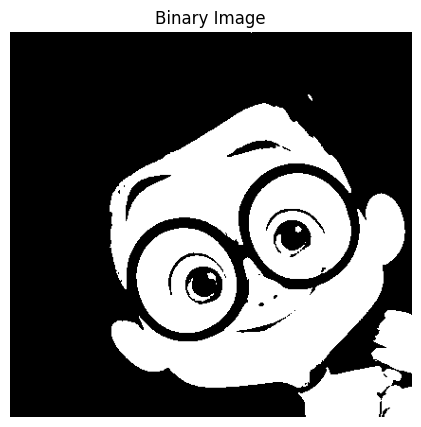

In [ ]:
plt.figure(figsize=(7, 5))

plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.show()

In [ ]:
structuring_element = np.ones((3, 3), dtype=bool)

In [ ]:
eroded = morphology.erosion(
    binary,
    footprint=structuring_element
)

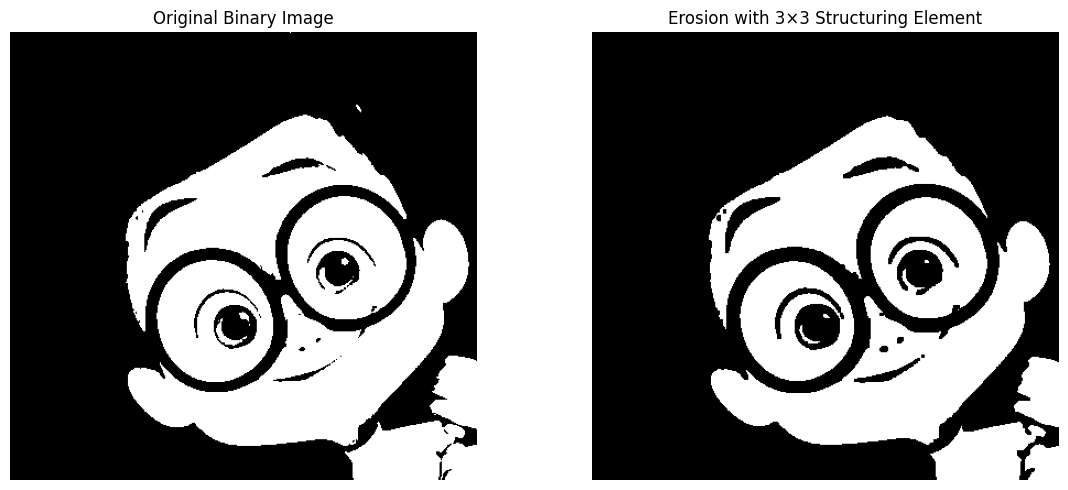

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("Original Binary Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(eroded, cmap="gray")
plt.title("Erosion with 3×3 Structuring Element")
plt.axis("off")

plt.tight_layout()
plt.show()

Erosion shrinks the white objects in a black-and-white image, making the edges pull inward and thin parts vanish